In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.cluster import KMeans
import warnings
warnings.filterwarnings('ignore')

In [2]:
df= pd.read_csv('data.csv', encoding='latin-1')
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [3]:
print(df.columns)
df.info()

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    541909 non-null  str    
 1   StockCode    541909 non-null  str    
 2   Description  540455 non-null  str    
 3   Quantity     541909 non-null  int64  
 4   InvoiceDate  541909 non-null  str    
 5   UnitPrice    541909 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      541909 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 33.1 MB


In [4]:
df.isna().sum()

InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [5]:
df['Country'].value_counts()

Country
United Kingdom          495478
Germany                   9495
France                    8557
EIRE                      8196
Spain                     2533
Netherlands               2371
Belgium                   2069
Switzerland               2002
Portugal                  1519
Australia                 1259
Norway                    1086
Italy                      803
Channel Islands            758
Finland                    695
Cyprus                     622
Sweden                     462
Unspecified                446
Austria                    401
Denmark                    389
Japan                      358
Poland                     341
Israel                     297
USA                        291
Hong Kong                  288
Singapore                  229
Iceland                    182
Canada                     151
Greece                     146
Malta                      127
United Arab Emirates        68
European Community          61
RSA                         58


In [6]:
df.drop(columns=['StockCode', 'Description', 'Country'], inplace=True)
print(df.columns)
df.head()

Index(['InvoiceNo', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID'], dtype='str')


,InvoiceNo,Quantity,InvoiceDate,UnitPrice,CustomerID
0,536365,6,12/1/2010 8:26,2.55,17850.0
1,536365,6,12/1/2010 8:26,3.39,17850.0
2,536365,8,12/1/2010 8:26,2.75,17850.0
3,536365,6,12/1/2010 8:26,3.39,17850.0
4,536365,6,12/1/2010 8:26,3.39,17850.0


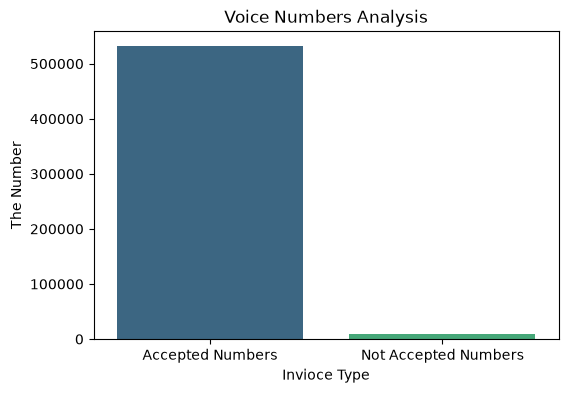

The Accepted No of Invoices: 532618
The Rejected No of Invoices: 9291


In [7]:
acc_len_Invoice= len(df[df['InvoiceNo'].astype(str).str.match('^[0-9]+$')])
Nacc_len_Invoice = len(df['InvoiceNo']) - acc_len_Invoice

x= ['Accepted Numbers', 'Not Accepted Numbers']
y= [acc_len_Invoice, Nacc_len_Invoice]

plt.figure(figsize=(6,4))
sns.barplot(x=x, y=y, palette='viridis')
plt.title("Voice Numbers Analysis")
plt.xlabel("Invioce Type")
plt.ylabel("The Number")
plt.show()

print(f"The Accepted No of Invoices: {acc_len_Invoice}")
print(f"The Rejected No of Invoices: {Nacc_len_Invoice}")


In [8]:
print(f"The Number of Unaccepted Values in Quantity = {len(df[df['Quantity'] <= 0])}")
print(f"The Number of Unaccepted Values in UnitPrice = {len(df[df['UnitPrice'] <= 0])}")

The Number of Unaccepted Values in Quantity = 10624
The Number of Unaccepted Values in UnitPrice = 2517


In [9]:
df_clean= df.dropna(subset=['CustomerID']).copy()

df_clean= df_clean[~df_clean['InvoiceNo'].astype(str).str.startswith('C')]
df_clean= df_clean[(df_clean['Quantity']> 0) & (df_clean['UnitPrice']> 0)]

print(f"Data Shape before cleaning: {df.shape}\n")
print(f"Data Shape after cleaning: {df_clean.shape}")

Data Shape before cleaning: (541909, 5)

Data Shape after cleaning: (397884, 5)


In [10]:
df_clean['TotalSum']= df_clean['Quantity']* df_clean['UnitPrice']
df_clean.drop(columns=['Quantity', 'UnitPrice'], inplace=True)
df_clean.head()

,InvoiceNo,InvoiceDate,CustomerID,TotalSum
0,536365,12/1/2010 8:26,17850.0,15.30
1,536365,12/1/2010 8:26,17850.0,20.34
2,536365,12/1/2010 8:26,17850.0,22.00
3,536365,12/1/2010 8:26,17850.0,20.34
4,536365,12/1/2010 8:26,17850.0,20.34


In [11]:
df_clean['InvoiceDate']= pd.to_datetime(df_clean['InvoiceDate'])

snapshot_date= df_clean['InvoiceDate'].max() + pd.Timedelta(days=1)
print(f"The reference date used to calculate the Recency is: {snapshot_date}")

The reference date used to calculate the Recency is: 2011-12-10 12:50:00


In [ ]:
rfm_table= df_clean.groupby('CustomerID').agg({
    'InvoiceDate': lambda x:(snapshot_date - x.max()).days,
    'InvoiceNo': 'nunique',
    'TotalSum': 'sum'
})

In [14]:
rfm_table.rename(columns={
    'InvoiceDate': 'Recency',
    'InvoiceNo': 'Frequency',
    'TotalSum': 'Monetary'
}, inplace= True)

print(rfm_table.shape)
rfm_table.head()

(4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,2,7,4310.00
12348.0,75,4,1797.24
12349.0,19,1,1757.55
12350.0,310,1,334.40


In [16]:
X= rfm_table[['Recency', 'Frequency', 'Monetary']]

pipeline= Pipeline([
    ('log_transform', FunctionTransformer(np.log1p, validate=False)),
    ('scaler', StandardScaler()),
    ('kmean', KMeans(n_clusters=4, random_state=42, n_init=10))
])

rfm_table['Cluster']= pipeline.fit_predict(X)
rfm_table.head()

,Recency,Frequency,Monetary,Cluster
CustomerID,,,,
12346.0,326,1,77183.60,2
12347.0,2,7,4310.00,1
12348.0,75,4,1797.24,2
12349.0,19,1,1757.55,0
12350.0,310,1,334.40,3
